# FarmTech Solutions — Fase 6 — Grupo 21
## Entrega 2: YOLO padrão e comparação das três abordagens

**Autor da contribuição original:** Elton Modesto de Souza Dias — **RM 572530**.  
**Equipe:** Lucas Carvalho Cordeiro (570388), Larissa da Silva Marcelino (571790), Elton Modesto de Souza Dias (572530) e Matheus Fontes (570457).  
**Tutora:** Nicolly Candida.

Este notebook reproduz a YOLOv5s padrão pré-treinada no COCO, sem ajuste aos dados do grupo, e compara seus resultados com a YOLO customizada de Lucas e a CNN de Matheus. **A CNN é uma arquitetura própria em Keras, com três blocos convolucionais, treinada do zero; não utiliza MobileNetV3.**

A contribuição original de Elton foi publicada inicialmente no repositório da Fase 5. Esta versão integra a solução ao repositório da Fase 6, corrige a documentação e a comparação e acrescenta imagens realmente processadas pela YOLO padrão. Os resultados originais permanecem registrados em [origem da contribuição](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/blob/main/docs/resultados/yolo_padrao/origem_contribuicao.json).

As saídas salvas desta versão foram geradas por uma nova execução da YOLO padrão em **CPU local** durante a integração. Os treinamentos da YOLO customizada e da CNN são os dos autores, preservados nos respectivos notebooks; não foram refeitos nesta execução.

### Como executar

1. No Colab, adicione a pasta FIAP_fase6_grupo21 do [Drive do grupo](https://drive.google.com/drive/folders/1T-mHMYGu8Nj33VuK808TOb8hT5D6Q5OT) a Meu Drive e execute as células na ordem.
2. Localmente, baixe a base preservando imagens e labels e configure a variável FARMTECH_DATASET_ROOT com a pasta organizado. Execute a partir da raiz deste repositório.
3. A execução verifica a base, carrega pesos COCO, avalia as oito fotos e salva previsões, caixas, galeria, métricas e informações do ambiente. Não há treinamento da YOLO padrão.

Referências: [código oficial YOLOv5 utilizado](https://github.com/ultralytics/yolov5/tree/f9578796b8a64889aa9e66dc06914d19f40d338e) e [carregamento oficial via PyTorch Hub](https://docs.ultralytics.com/yolov5/tutorials/pytorch-hub-model-loading/).


## 1. Preparar o ambiente e acessar a base

Usamos as mesmas classes e a separação 64/8/8 da Entrega 1. A base do Drive é somente lida; os resultados ficam em uma pasta separada. No Colab, a montagem do Drive requer autorização de acesso.


In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

# Instala somente bibliotecas ausentes. Torch e torchvision já vêm no Colab.
requisitos = {'torch': 'torch', 'torchvision': 'torchvision', 'ultralytics': 'ultralytics>=8.4.164',
              'yaml': 'PyYAML', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
faltantes = [pacote for modulo, pacote in requisitos.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltantes], check=True)

try:
    from google.colab import drive
except ImportError:
    EM_COLAB = False
else:
    drive.mount('/content/drive')
    EM_COLAB = True

PROJETO = Path.cwd()
DRIVE_PROJECT = Path('/content/drive/MyDrive/FIAP_fase6_grupo21')
candidatos = [Path(os.environ['FARMTECH_DATASET_ROOT'])] if os.environ.get('FARMTECH_DATASET_ROOT') else []
candidatos += [DRIVE_PROJECT / 'dataset_yolo/organizado',
               Path('/content/drive/MyDrive/FIAP/FASE-06/dataset_yolo/organizado'),
               PROJETO / 'dataset_yolo/organizado', Path('/content/dataset_yolo/organizado')]
DATASET_ROOT = next((p for p in candidatos if (p / 'data.yaml').is_file()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError('Adicione a base organizada do grupo ao Drive ou configure FARMTECH_DATASET_ROOT. Não crie uma nova separação das imagens.')

OUTPUT_DIR = (DRIVE_PROJECT / 'resultados_yolo_padrao') if EM_COLAB else PROJETO / 'docs/resultados/yolo_padrao'
FIG_DIR = (OUTPUT_DIR / 'imagens') if EM_COLAB else PROJETO / 'docs/figuras/yolo_padrao'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Ambiente:', 'Google Colab' if EM_COLAB else 'local')
print('Base:', DATASET_ROOT)
print('Resultados:', OUTPUT_DIR)


Ambiente: local
Base: /tmp/farmtech_drive_confirmado
Resultados: /tmp/farmtech-grupo21-readme/docs/resultados/yolo_padrao


## 2. Conferir a base e as oito fotos de teste

Não treinamos nem ajustamos a YOLO padrão neste notebook. A validação continua separada do teste. Conferimos as contagens, os pares imagem/marcação e os hashes das fotos de teste em relação ao manifesto da base compartilhada.

Cada foto tem uma classe alvo, mas pode conter vários objetos dessa classe. O acerto por foto avalia a classe; não verifica se todos os objetos foram localizados corretamente.


In [2]:
import hashlib
import io
import pandas as pd
import yaml
from urllib.request import urlopen

REPO_RAW = 'https://raw.githubusercontent.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/main/'
def ler_arquivo_projeto(caminho):
    local = PROJETO / caminho
    if local.is_file():
        return local.read_bytes()
    with urlopen(REPO_RAW + caminho, timeout=30) as resposta:
        return resposta.read()

with open(DATASET_ROOT / 'data.yaml', encoding='utf-8') as arquivo:
    nomes = yaml.safe_load(arquivo)['names']
if isinstance(nomes, list):
    nomes = dict(enumerate(nomes))
else:
    nomes = {int(k): v for k, v in nomes.items()}
assert nomes == {0: 'banana', 1: 'garrafa_pet'}, nomes

def classe_real(imagem, split='test'):
    caminho = DATASET_ROOT / 'labels' / split / f'{imagem.stem}.txt'
    ids = {int(linha.split()[0]) for linha in caminho.read_text().splitlines() if linha.strip()}
    if len(ids) != 1:
        raise ValueError(f'{imagem.name}: esperada uma classe alvo por foto, encontrado {ids}.')
    return nomes[ids.pop()]

contagens = []
for split, por_classe in [('train', 32), ('val', 4), ('test', 4)]:
    fotos = sorted(p for p in (DATASET_ROOT / 'images' / split).iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    reais = [classe_real(p, split) for p in fotos]
    for classe in nomes.values():
        quantidade = reais.count(classe)
        assert quantidade == por_classe, (split, classe, quantidade)
        contagens.append({'conjunto': split, 'classe': classe, 'fotos': quantidade})

imagens_teste = sorted(p for p in (DATASET_ROOT / 'images/test').iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
manifesto = pd.read_csv(io.BytesIO(ler_arquivo_projeto('data/manifesto.csv')))
manifesto_teste = manifesto[manifesto['conjunto'] == 'test'].set_index('arquivo')
assert set(p.name for p in imagens_teste) == set(manifesto_teste.index)
for p in imagens_teste:
    assert hashlib.sha256(p.read_bytes()).hexdigest() == manifesto_teste.loc[p.name, 'sha256_imagem'], p.name
display(pd.DataFrame(contagens))
print('Teste: 8 fotos, nomes e hashes conferidos; separação preservada.')


,conjunto,classe,fotos
0,train,banana,32
1,train,garrafa_pet,32
2,val,banana,4
3,val,garrafa_pet,4
4,test,banana,4
5,test,garrafa_pet,4


Teste: 8 fotos, nomes e hashes conferidos; separação preservada.


## 3. Carregar a YOLO padrão e registrar o dispositivo

Carregamos YOLOv5s com pesos COCO, sem treinar na base do grupo. COCO contém banana e bottle; a classe bottle inclui garrafas em geral e funciona aqui como aproximação de garrafa PET. Isso limita a equivalência semântica com a classe treinada na YOLO customizada.

Mantemos confiança mínima 0,25, IoU de NMS 0,60, lote de uma foto e tamanho configurado 640. O dispositivo e as versões são registrados. A CPU usa até quatro threads para evitar excesso de threads neste teste pequeno.


In [3]:
import platform
import time
import torch
import torchvision
import ultralytics

YOLO_COMMIT = 'f9578796b8a64889aa9e66dc06914d19f40d338e'
DISPOSITIVO = 'cuda:0' if torch.cuda.is_available() else 'cpu'
if DISPOSITIVO == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))

# Usa a mesma revisão oficial de código registrada na Entrega 1.
repositorio_local = os.environ.get('FARMTECH_YOLO_SOURCE')
if repositorio_local:
    modelo = torch.hub.load(repositorio_local, 'yolov5s', source='local', pretrained=True, device=DISPOSITIVO, _verbose=False)
else:
    modelo = torch.hub.load(f'ultralytics/yolov5:{YOLO_COMMIT}', 'yolov5s', pretrained=True,
                            trust_repo=True, skip_validation=True, device=DISPOSITIVO, _verbose=False)
modelo.eval()
modelo.conf = 0.25
modelo.iou = 0.60
modelo.classes = [39, 46]
assert modelo.names[39] == 'bottle' and modelo.names[46] == 'banana'
COCO_PARA_PROJETO = {'banana': 'banana', 'bottle': 'garrafa_pet'}
hardware = torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor() or 'CPU'
try:
    cpu_model = next(linha.split(':', 1)[1].strip() for linha in Path('/proc/cpuinfo').read_text().splitlines() if linha.startswith('model name'))
except (OSError, StopIteration):
    cpu_model = hardware
ambiente = {'python': platform.python_version(), 'pytorch': torch.__version__,
            'torchvision': torchvision.__version__, 'ultralytics': ultralytics.__version__,
            'sistema': platform.system(), 'dispositivo': DISPOSITIVO, 'hardware': hardware,
            'cpu': cpu_model, 'threads_cpu': torch.get_num_threads(),
            'yolo_commit': YOLO_COMMIT, 'batch_size': 1, 'imgsz': 640,
            'precisao_numerica': 'FP32'}
print(ambiente)


WARNING ⚠️ user config directory '/tmp/farmtech_yolo_config/Ultralytics' is not writable, using '/tmp/Ultralytics'. Set YOLO_CONFIG_DIR to override.


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/tmp/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


{'python': '3.12.3', 'pytorch': '2.14.1+cpu', 'torchvision': '0.29.1+cpu', 'ultralytics': '8.4.176', 'sistema': 'Linux', 'dispositivo': 'cpu', 'hardware': 'x86_64', 'cpu': 'Intel(R) Core(TM) 7 150U', 'threads_cpu': 4, 'yolo_commit': 'f9578796b8a64889aa9e66dc06914d19f40d338e', 'batch_size': 1, 'imgsz': 640, 'precisao_numerica': 'FP32'}


## 4. Avaliar a classe e guardar as caixas reais

Para a comparação por foto, filtramos banana e bottle, escolhemos a detecção de maior confiança e contamos ausência de detecção como erro. Usamos a mesma regra aplicada à YOLO customizada.

O tempo medido envolve a chamada AutoShape com o caminho da foto: leitura, preparação, cálculo e filtragem das caixas. A conversão em tabela, o desenho e a gravação ficam fora da medição. Carregamento dos pesos e aquecimento também ficam fora. Na GPU, sincronizamos antes e depois para medir a operação concluída.


In [4]:
from PIL import Image

def sincronizar():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# Aquecimento não entra na média.
with torch.inference_mode():
    _ = modelo(str(imagens_teste[0]), size=640)
sincronizar()
linhas, caixas, imagens_processadas = [], [], []
with torch.inference_mode():
    for imagem in imagens_teste:
        sincronizar()
        inicio = time.perf_counter()
        resultado = modelo(str(imagem), size=640)
        sincronizar()
        tempo_ms = (time.perf_counter() - inicio) * 1000
        deteccoes = resultado.pandas().xyxy[0]
        deteccoes = deteccoes[deteccoes['name'].isin(COCO_PARA_PROJETO)]
        if deteccoes.empty:
            predicao, confianca = 'sem_deteccao', None
        else:
            melhor = deteccoes.sort_values('confidence', ascending=False).iloc[0]
            predicao = COCO_PARA_PROJETO[melhor['name']]
            confianca = float(melhor['confidence'])
        real = classe_real(imagem)
        linhas.append({'arquivo': imagem.name, 'classe_real': real, 'predicao_yolo_padrao': predicao,
                       'confianca': confianca, 'acertou': predicao == real, 'tempo_inferencia_ms': tempo_ms,
                       'sha256_imagem': hashlib.sha256(imagem.read_bytes()).hexdigest()})
        for _, caixa in deteccoes.iterrows():
            caixas.append({'arquivo': imagem.name, 'classe_coco': caixa['name'],
                           'classe_projeto': COCO_PARA_PROJETO[caixa['name']],
                           'confianca': float(caixa['confidence']),
                           **{k: float(caixa[k]) for k in ['xmin', 'ymin', 'xmax', 'ymax']}})
        # render usa somente as caixas previstas pela rede, não as marcações de referência.
        processada = Image.fromarray(resultado.render()[0])
        processada.thumbnail((1000, 1000))
        processada.save(FIG_DIR / imagem.name, quality=90)
        imagens_processadas.append(processada)

predicoes = pd.DataFrame(linhas)
caixas_df = pd.DataFrame(caixas, columns=['arquivo', 'classe_coco', 'classe_projeto', 'confianca', 'xmin', 'ymin', 'xmax', 'ymax'])
display(predicoes[['arquivo', 'classe_real', 'predicao_yolo_padrao', 'confianca', 'acertou', 'tempo_inferencia_ms']])


,arquivo,classe_real,predicao_yolo_padrao,confianca,acertou,tempo_inferencia_ms
0,20261009_191256.jpg,garrafa_pet,garrafa_pet,0.776662,True,307.124224
1,20261011_220831.jpg,banana,banana,0.870694,True,333.707484
2,20261011_221012.jpg,banana,banana,0.676561,True,311.312472
3,IMG-20261005-WA0006.jpg,banana,banana,0.668321,True,168.932581
4,IMG-20261005-WA0008.jpg,banana,banana,0.420468,True,159.904101
5,IMG-20261005-WA0044.jpg,garrafa_pet,sem_deteccao,NaN,False,195.198527
6,IMG-20261005-WA0060.jpg,garrafa_pet,sem_deteccao,NaN,False,223.841519
7,IMG-20261005-WA0112.jpg,garrafa_pet,sem_deteccao,NaN,False,139.504975


## 5. Visualizar acertos e erros

As caixas abaixo são detecções da YOLO padrão. Uma foto sem caixas indica que o modelo não encontrou banana ou bottle acima do limite de confiança. A legenda informa a classe real e a classe prevista; o nome bottle impresso na caixa é a classe original COCO.


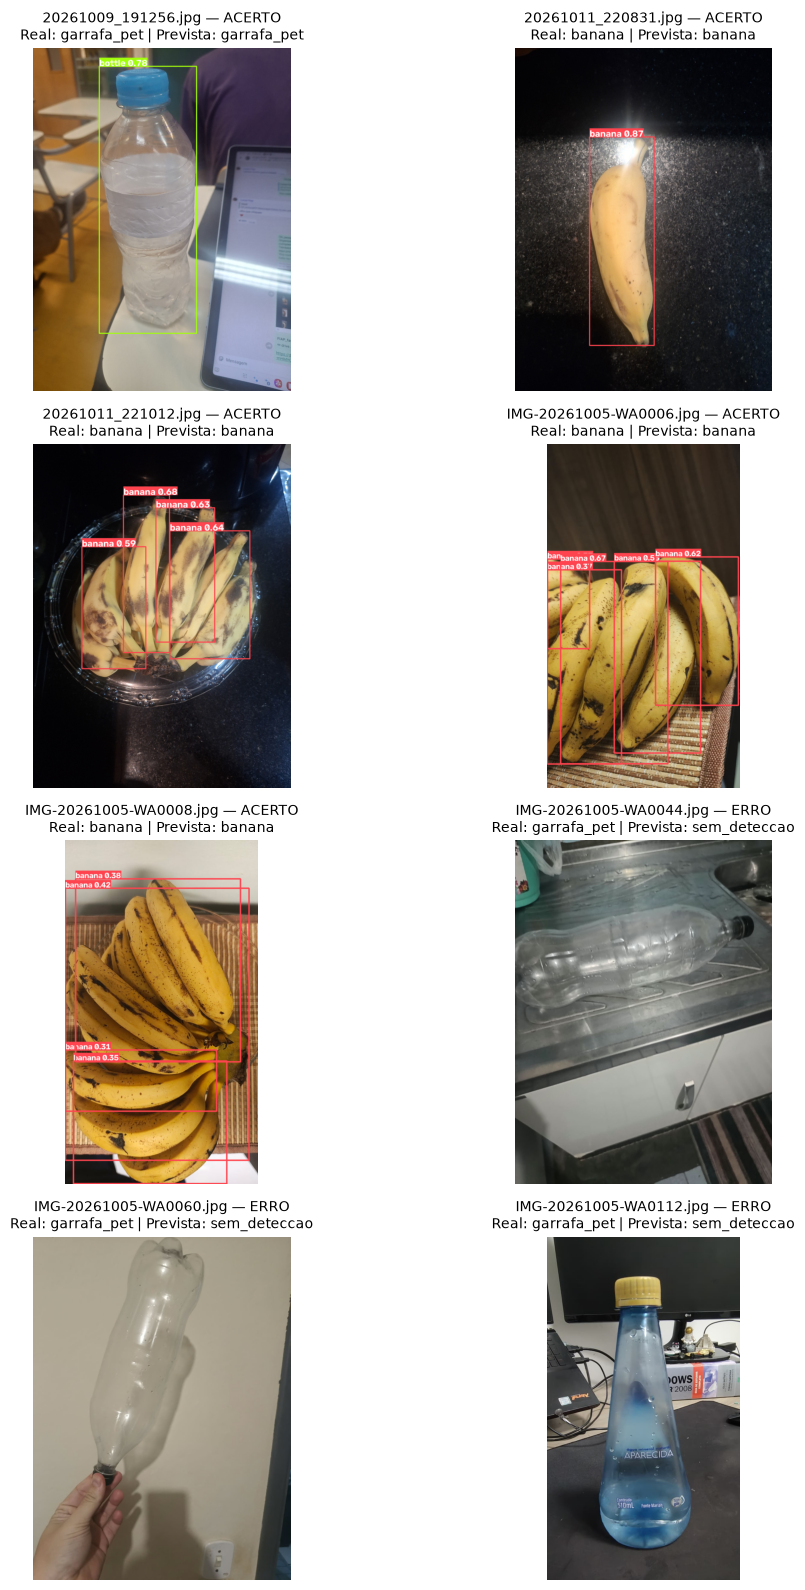

In [5]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(4, 2, figsize=(12, 16))
for eixo, imagem, linha in zip(eixos.flat, imagens_processadas, linhas):
    eixo.imshow(imagem)
    estado = 'ACERTO' if linha['acertou'] else 'ERRO'
    eixo.set_title(f"{linha['arquivo']} — {estado}\nReal: {linha['classe_real']} | Prevista: {linha['predicao_yolo_padrao']}", fontsize=10)
    eixo.axis('off')
fig.tight_layout()
fig.savefig(FIG_DIR / 'galeria_teste.png', dpi=120, bbox_inches='tight')
plt.show()


## 6. Salvar resultados e separar a execução original da reprodução

Os tempos desta reprodução pertencem ao ambiente registrado acima. A execução original de Elton acertou 5/8 fotos e registrou aproximadamente 937,41 ms por foto em CPU. Preservamos esse registro sem substituir seu tempo pelo desta máquina.

Uma repetição das mesmas fotos verifica a implementação, mas não representa um novo conjunto independente de teste nem aumenta a amostra de oito imagens.


In [6]:
import json

resumo_padrao = {'modelo': 'YOLOv5s padrão pré-treinada no COCO',
                 'regra_avaliacao': 'maior confiança >= 0.25 entre banana e bottle; sem detecção é erro',
                 'imagens_teste': len(predicoes), 'acertos': int(predicoes['acertou'].sum()),
                 'acuracia_por_imagem': float(predicoes['acertou'].mean()),
                 'erro_por_imagem': float(1 - predicoes['acertou'].mean()),
                 'tempo_medio_inferencia_ms': float(predicoes['tempo_inferencia_ms'].mean()),
                 'escopo_tempo': 'AutoShape sobre o caminho da foto: leitura/preparação, modelo e NMS; fora da medição: carregar pesos, aquecimento, conversão em tabela, render e salvar.',
                 'limite_confianca': modelo.conf, 'iou_nms': modelo.iou,
                 'treinamento_nesta_base': False, 'pesos': 'yolov5s COCO', 'ambiente': ambiente}
predicoes.to_csv(OUTPUT_DIR / 'predicoes_yolo_padrao.csv', index=False)
caixas_df.to_csv(OUTPUT_DIR / 'caixas_yolo_padrao.csv', index=False)
(OUTPUT_DIR / 'resultado_yolo_padrao.json').write_text(json.dumps(resumo_padrao, ensure_ascii=False, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'ambiente_execucao.json').write_text(json.dumps(ambiente, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(resumo_padrao, ensure_ascii=False, indent=2))


{
  "modelo": "YOLOv5s padrão pré-treinada no COCO",
  "regra_avaliacao": "maior confiança >= 0.25 entre banana e bottle; sem detecção é erro",
  "imagens_teste": 8,
  "acertos": 5,
  "acuracia_por_imagem": 0.625,
  "erro_por_imagem": 0.375,
  "tempo_medio_inferencia_ms": 229.9407353712013,
  "escopo_tempo": "AutoShape sobre o caminho da foto: leitura/preparação, modelo e NMS; fora da medição: carregar pesos, aquecimento, conversão em tabela, render e salvar.",
  "limite_confianca": 0.25,
  "iou_nms": 0.6,
  "treinamento_nesta_base": false,
  "pesos": "yolov5s COCO",
  "ambiente": {
    "python": "3.12.3",
    "pytorch": "2.14.1+cpu",
    "torchvision": "0.29.1+cpu",
    "ultralytics": "8.4.176",
    "sistema": "Linux",
    "dispositivo": "cpu",
    "hardware": "x86_64",
    "cpu": "Intel(R) Core(TM) 7 150U",
    "threads_cpu": 4,
    "yolo_commit": "f9578796b8a64889aa9e66dc06914d19f40d338e",
    "batch_size": 1,
    "imgsz": 640,
    "precisao_numerica": "FP32"
  }
}


## 7. Comparar acertos por foto no teste

Esta é a comparação comum: acertar a classe presente em cada uma das oito fotos reservadas. Os arquivos de referência apontam para os resultados executados de Lucas e Matheus. A saída da CNN é a classe da foto e não fornece caixas.

A CNN usa seu critério binário de classificação. As YOLOs escolhem a detecção de maior confiança entre as duas classes alvo e podem não produzir detecção. Portanto, a medida é comum, mas os mecanismos de previsão têm diferenças que devem ser consideradas.


In [7]:
referencias = json.loads(ler_arquivo_projeto('docs/resultados/yolo_padrao/referencias_comparacao.json'))
custom = referencias['yolo_customizada']
cnn = referencias['cnn']
acertos_custom = pd.read_csv(io.BytesIO(ler_arquivo_projeto(custom['fonte_acertos'])))
assert set(acertos_custom['Foto']) == set(predicoes['arquivo'])
assert all(acertos_custom.set_index('Foto').loc[r['arquivo'], 'Esperado'] == r['classe_real'] for r in linhas)
n_custom = int(acertos_custom['Acertou'].eq('Sim').sum())

comparacao = pd.DataFrame([
    {'abordagem': 'YOLO customizada', 'acertos': n_custom, 'fotos': len(acertos_custom), 'acerto_percentual': n_custom / len(acertos_custom) * 100, 'origem': 'Lucas — teste reservado'},
    {'abordagem': 'YOLO padrão COCO', 'acertos': resumo_padrao['acertos'], 'fotos': resumo_padrao['imagens_teste'], 'acerto_percentual': resumo_padrao['acuracia_por_imagem'] * 100, 'origem': 'Reprodução da contribuição de Elton'},
    {'abordagem': 'CNN do zero', 'acertos': cnn['acertos'], 'fotos': cnn['fotos_teste'], 'acerto_percentual': cnn['acuracia'] * 100, 'origem': 'Matheus — teste reservado'},
])
comparacao['erro_percentual'] = 100 - comparacao['acerto_percentual']
comparacao.to_csv(OUTPUT_DIR / 'comparacao_acertos_teste.csv', index=False)
display(comparacao)

# Valores por foto: CNN acertou todas as fotos na matriz e galeria salvas por Matheus.
por_foto = predicoes[['arquivo', 'classe_real', 'predicao_yolo_padrao', 'acertou']].rename(columns={'acertou': 'yolo_padrao_acertou'})
por_foto = por_foto.merge(acertos_custom[['Foto', 'Previsto', 'Acertou']].rename(columns={'Foto': 'arquivo', 'Previsto': 'predicao_yolo_customizada', 'Acertou': 'yolo_customizada_acertou'}), on='arquivo', validate='one_to_one')
por_foto['cnn_acertou'] = True
por_foto['fonte_cnn'] = cnn['notebook'] + ' — matriz e galeria salvas (8/8)'
por_foto.to_csv(OUTPUT_DIR / 'comparacao_por_foto.csv', index=False)
display(por_foto[['arquivo', 'classe_real', 'yolo_customizada_acertou', 'yolo_padrao_acertou', 'cnn_acertou']])


,abordagem,acertos,fotos,acerto_percentual,origem,erro_percentual
0,YOLO customizada,7,8,87.5,Lucas — teste reservado,12.5
1,YOLO padrão COCO,5,8,62.5,Reprodução da contribuição de Elton,37.5
2,CNN do zero,8,8,100.0,Matheus — teste reservado,0.0


,arquivo,classe_real,yolo_customizada_acertou,yolo_padrao_acertou,cnn_acertou
0,20261009_191256.jpg,garrafa_pet,Sim,True,True
1,20261011_220831.jpg,banana,Sim,True,True
2,20261011_221012.jpg,banana,Sim,True,True
3,IMG-20261005-WA0006.jpg,banana,Sim,True,True
4,IMG-20261005-WA0008.jpg,banana,Sim,True,True
5,IMG-20261005-WA0044.jpg,garrafa_pet,Não,False,True
6,IMG-20261005-WA0060.jpg,garrafa_pet,Sim,False,True
7,IMG-20261005-WA0112.jpg,garrafa_pet,Sim,False,True


## 8. Apresentar as métricas de detecção separadamente

Os 90,00% de mAP@50 da YOLO customizada pertencem à validação e serviram para selecionar o experimento. No teste, mAP@50 é 83,74% e mAP@50–95 é 55,63%. Esses valores avaliam as caixas e não são os 87,50% de acerto da classe por foto.

Não calculamos mAP da YOLO padrão nesta contribuição; isso não significa mAP igual a zero. A CNN não produz caixas, portanto mAP de detecção não se aplica a ela.


In [8]:
metricas = custom['metricas_teste']
detecao = pd.DataFrame([{'abordagem': 'YOLO customizada — teste', 'precisao_percentual': metricas['precisao'] * 100,
                        'recall_percentual': metricas['recall'] * 100, 'mAP50_percentual': metricas['map50'] * 100,
                        'mAP50_95_percentual': metricas['map50_95'] * 100}])
detecao.to_csv(OUTPUT_DIR / 'metricas_detecao_teste.csv', index=False)
display(detecao)


,abordagem,precisao_percentual,recall_percentual,mAP50_percentual,mAP50_95_percentual
0,YOLO customizada — teste,90.865165,72.916667,83.74286,55.629829


## 9. Comparar esforço e tempos com as condições registradas

Estas medições descrevem cada execução; não constituem um teste controlado de velocidade entre arquiteturas. Hardware, tamanho de entrada, lote e etapas medidas são diferentes. Mesmo duas execuções em CPU podem usar processadores, número de threads e bibliotecas diferentes.

YOLO padrão não foi treinada na base do grupo: o campo de treinamento é “não aplicável”, em vez de apresentar zero como se fosse um tempo medido. Na YOLO customizada, o tempo envolve o processo de treinamento, validações e gravações; na CNN é a chamada de treinamento registrada pelo autor.


In [9]:
tempos = pd.DataFrame([
    {'abordagem': 'YOLO customizada', 'treinamento_segundos': custom['tempo_treinamento_s'], 'epocas': 60,
     'inferencia_ms_por_foto': custom['tempos']['inferencia_modelo_ms_por_foto'], 'hardware': 'GPU Tesla T4',
     'entrada': '640 configurado; entradas retangulares', 'lote_inferencia': 1,
     'escopo_inferencia': 'Cálculo da rede; preparação 0,50 ms e NMS 21,40 ms separados; não é a aplicação completa'},
    {'abordagem': 'YOLO padrão COCO — reprodução', 'treinamento_segundos': None, 'epocas': None,
     'inferencia_ms_por_foto': resumo_padrao['tempo_medio_inferencia_ms'], 'hardware': ambiente['hardware'] + ' / ' + ambiente['cpu'],
     'entrada': '640 configurado; AutoShape preserva proporção', 'lote_inferencia': 1,
     'escopo_inferencia': resumo_padrao['escopo_tempo']},
    {'abordagem': 'CNN do zero', 'treinamento_segundos': cnn['tempo_treinamento_s'], 'epocas': cnn['epocas'],
     'inferencia_ms_por_foto': cnn['tempo_inferencia_ms_por_foto'], 'hardware': cnn['hardware'],
     'entrada': cnn['entrada'], 'lote_inferencia': cnn['batch_size'], 'escopo_inferencia': cnn['escopo_tempo']},
])
tempos.to_csv(OUTPUT_DIR / 'comparacao_tempos_condicoes.csv', index=False)
display(tempos)


,abordagem,treinamento_segundos,epocas,inferencia_ms_por_foto,hardware,entrada,lote_inferencia,escopo_inferencia
0,YOLO customizada,161.160705,60.0,17.300000,GPU Tesla T4,640 configurado; entradas retangulares,1,"Cálculo da rede; preparação 0,50 ms e NMS 21,4..."
1,YOLO padrão COCO — reprodução,NaN,NaN,229.940735,x86_64 / Intel(R) Core(TM) 7 150U,640 configurado; AutoShape preserva proporção,1,AutoShape sobre o caminho da foto: leitura/pre...
2,CNN do zero,15.600000,30.0,9.400000,CPU local (execução de Matheus),128 x 128,8,"Tempo de predict sobre o conjunto de teste, ap..."


## 10. Avaliação crítica e conclusão

### Facilidade de uso e integração

- **YOLO padrão:** exige instalar a biblioteca e carregar pesos prontos, sem marcação nem treinamento específicos para iniciar uma demonstração. Exige mapear banana e bottle para as classes do projeto; bottle não distingue material PET. Também fornece caixas.
- **YOLO customizada:** exige preparar imagens, marcar caixas, configurar treino e comparar épocas. Aproveita pesos pré-treinados e aprende as classes do grupo. É adequada quando precisamos identificar a classe e a localização dos objetos; as caixas permitem observar instâncias que a classificação por foto esconde.
- **CNN do zero:** usa uma arquitetura própria em Keras, com Conv2D 16/32/64, camadas densas e sigmoid. Não exige caixas para classificar, embora esta implementação leia os labels existentes para converter uma cópia da base em pastas por classe. Utiliza TensorFlow e bibliotecas de apoio. Diz qual classe está na foto, mas não onde o objeto está.

### Qualidade e limitações

Na comparação das oito fotos, a YOLO customizada acertou 7/8, a YOLO padrão original de Elton acertou 5/8 e a CNN acertou 8/8. A tabela executada acima registra o resultado da reprodução atual da YOLO padrão. No registro original, as quatro fotos de banana foram corretas e três das quatro garrafas ficaram sem detecção. A garrafa deitada na pia não foi detectada por nenhuma das YOLOs; a CNN classificou corretamente a classe da foto.

Os 100% da CNN representam apenas oito fotos. Não comprovam desempenho universal nem localização correta. Um acerto a mais ou a menos muda o resultado em 12,5 pontos percentuais. A base contém somente duas classes, uma classe alvo por foto, poucas variações e nenhuma avaliação específica de cenas com as duas classes juntas ou sem os objetos.

O acerto da classe por foto não exige encontrar todas as bananas de um cacho. Para a YOLO customizada, mAP e recall complementam essa medida. A classe bottle do COCO tem significado mais amplo que garrafa PET, e a escolha de confiança 0,25 afeta a possibilidade de não haver detecção. O teste foi mantido sem reajustar os parâmetros após observar seus erros.

### Treinamento e inferência

A YOLO customizada teve execução de 60 épocas em aproximadamente 161,16 s na T4; a CNN teve treinamento de 30 épocas em 15,6 s em CPU. A YOLO padrão usou pesos prontos e não foi treinada neste conjunto. Esses tempos pertencem às condições registradas e não isolam o efeito da arquitetura.

As medidas de inferência não permitem afirmar que uma rede seja intrinsecamente mais rápida: a YOLO customizada informa 17,30 ms do cálculo da rede na T4, a CNN informa 9,4 ms por foto a partir de predict em lote de oito em CPU, e a YOLO padrão mede a chamada AutoShape em CPU, incluindo leitura e preparação. Um experimento futuro de velocidade deve fixar hardware, resolução, lote, aquecimento e etapas incluídas.

### Escolha conforme a aplicação

Para localizar os objetos deste cenário, a YOLO customizada é a candidata mais adequada entre as implementações avaliadas: fornece caixas e recuperou mais fotos de garrafa que a padrão. Para classificar fotos com uma única classe alvo, a CNN é uma candidata simples e obteve todos os acertos nesta amostra. A YOLO padrão é uma referência útil para começar sem treino, com a limitação de sua classe bottle e dos erros observados.

Precisamos ampliar e diversificar as imagens para investigar generalização. Neste trabalho, as evidências sustentam uma demonstração acadêmica e uma escolha ligada ao cenário, sem declarar uma solução universalmente superior.

## 11. Evidências e acesso às contribuições

- [YOLO customizada — Lucas](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/blob/main/notebooks/LucasCarvalhoCordeiro_rm570388_pbl_fase6.ipynb).
- [CNN do zero — Matheus](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/blob/main/MatheusFontes_rm570457_pbl_fase6.ipynb).
- [Resumo e arquivos desta execução](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/tree/main/docs/resultados/yolo_padrao).
- [Imagens processadas](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/tree/main/docs/figuras/yolo_padrao).

O notebook original de Elton e seus resultados estão identificados no registro de origem. A reprodução executa novamente somente a YOLO padrão e a consolidação da comparação. Os códigos e as saídas dos treinamentos de Lucas e Matheus permanecem preservados. O vídeo final deverá demonstrar as três abordagens e suas limitações a partir destes notebooks.
